# Linear discriminant analysis as a dimension reduction technique

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

With $K$ classes, the $K$ centroids of LDA lie in a subspace of dimension at most $K-1$. To classify, only the position of an observation in that subspace matters. Moreover, we can look for the directions of that subspace in which the centroids are most spread with respect to the variability within the classes (Fisher): they are the eigenvectors of $W^{-1}B$, where $W$ is the within-class covariance matrix and $B$ the covariance matrix of the centroids. Projecting on the first two or three *discriminant coordinates* gives the best low-dimensional picture of the classes.

We use the vowel data of the notebook `21_classification_vowels`: 11 vowels and 10 features.

In [2]:
dat_train = pd.read_csv('vowel_train.csv')
dat_train = dat_train.drop('row.names', axis=1)
n_train = dat_train.shape[0]

dat_test = pd.read_csv('vowel_test.csv')
dat_test = dat_test.drop('row.names', axis=1)
n_test = dat_test.shape[0]

features = dat_train.columns.drop('y')
classes = np.sort(dat_train['y'].unique())

lda = LinearDiscriminantAnalysis(store_covariance=True)
lda.fit(dat_train[features], dat_train['y'])

lda.means_.shape

(11, 10)

## Discriminant coordinates by hand

In [3]:
B = np.cov(lda.means_.T)
W = lda.covariance_
A = np.linalg.solve(W, B)

# The eigenvalues are real, but numerically they can come with a null imaginary part and without order
eigenvalues, eigenvectors = np.linalg.eig(A)
order = np.argsort(-eigenvalues.real)
eigenvalues = eigenvalues.real[order]
eigenvectors = eigenvectors.real[:, order]

np.round(eigenvalues, 4)

array([4.4572e+00, 2.7920e+00, 3.5340e-01, 1.5190e-01, 8.4600e-02,
       6.5800e-02, 2.0500e-02, 8.5000e-03, 1.1000e-03, 7.0000e-04])

The eigenvalues measure how separated the centroids are along each coordinate. The first two concentrate most of the separation.

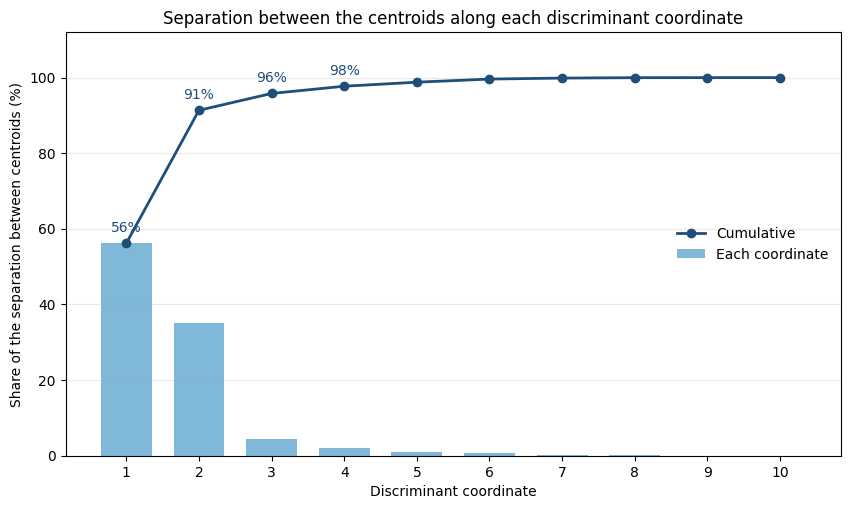

In [4]:
share = eigenvalues/eigenvalues.sum()

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(range(1, 11), 100*share, color='#7fb8d8', width=0.7, label='Each coordinate')
ax.plot(range(1, 11), 100*np.cumsum(share), 'o-', color='#1f4e79', lw=2, label='Cumulative')
for i, value in enumerate(100*np.cumsum(share)[:4]):
    ax.annotate(f'{value:.0f}%', (i+1, value), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=10,
                color='#1f4e79')
ax.set_xticks(range(1, 11))
ax.set_ylim(0, 112)
ax.set_xlabel('Discriminant coordinate')
ax.set_ylabel('Share of the separation between centroids (%)')
ax.set_title('Separation between the centroids along each discriminant coordinate')
ax.legend(loc='center right', frameon=False)
ax.grid(True, axis='y', alpha=0.25)

In [5]:
coordinate_names = [f'coordinate {j+1}' for j in range(10)]

discriminant_coordinates = pd.DataFrame(dat_train[features].to_numpy() @ eigenvectors, columns=coordinate_names)
discriminant_coordinates.insert(0, 'y', dat_train['y'])

discriminant_coordinates

,y,coordinate 1,coordinate 2,coordinate 3,coordinate 4,coordinate 5,coordinate 6,coordinate 7,coordinate 8,coordinate 9,coordinate 10
0,1,1.517390,-2.140100,0.210153,-0.508985,-0.103767,0.999575,1.329825,-1.305993,0.425513,-0.080684
1,2,1.658575,-2.089806,0.184112,-0.571827,-0.280268,0.567684,1.318574,-1.077016,0.522652,0.050418
2,3,1.108271,-0.748151,-0.440077,-1.040719,-0.653076,0.553894,1.741206,-0.800437,0.317096,-0.160534
3,4,1.416722,-0.401345,-0.189262,-0.088877,-0.592158,0.785724,1.368863,-1.174486,0.763565,0.402269
4,5,1.962531,-0.395232,0.677784,0.319218,0.051803,0.450937,1.405916,-0.784956,0.457219,0.528598
...,...,...,...,...,...,...,...,...,...,...,...
523,7,2.737455,-1.006794,-0.043572,-0.306622,0.503144,0.587053,1.668281,-0.877435,-0.802783,-1.111057
524,8,3.691611,-1.435311,-1.063308,0.091163,-0.549378,0.164329,1.347793,-0.646040,-0.377756,-0.476523
525,9,3.021255,-1.253761,-1.023252,0.050950,-0.745909,0.214404,1.250031,-0.929463,0.322975,-1.604033
526,10,3.369093,-0.981319,-1.416394,0.992495,-0.521514,0.288212,1.594424,-0.726085,0.459569,-0.608309


In [6]:
projected_means = pd.DataFrame(lda.means_ @ eigenvectors, columns=coordinate_names)
projected_means.insert(0, 'y', classes)

projected_means

,y,coordinate 1,coordinate 2,coordinate 3,coordinate 4,coordinate 5,coordinate 6,coordinate 7,coordinate 8,coordinate 9,coordinate 10
0,1,1.309440,-2.183706,0.184196,-0.132992,0.181547,0.542352,1.091716,-0.538062,0.050363,-0.126659
1,2,1.315812,-1.638201,-0.277394,-0.341065,0.082739,0.374756,1.014228,-0.559374,0.064748,-0.103578
2,3,1.076409,-1.063016,-0.472189,-0.192610,0.169203,0.518262,1.106969,-0.552589,0.075910,-0.150488
3,4,1.294645,-0.473148,-0.299930,0.038269,0.044958,0.522387,1.059195,-0.549072,0.033576,-0.111142
4,5,2.216777,-0.498109,0.166694,-0.156463,-0.026802,0.473582,1.076962,-0.614954,0.074530,-0.128160
5,6,1.876342,-0.702694,0.003836,-0.100845,0.104046,0.366795,1.093508,-0.446557,0.059305,-0.135720
6,7,2.682013,-0.746928,-0.093201,-0.342904,0.192732,0.549050,0.967604,-0.514814,0.055428,-0.137877
7,8,3.437224,-0.991669,-0.232643,-0.225485,0.264211,0.487581,1.136978,-0.545291,0.060307,-0.103611
8,9,2.881095,-1.537206,-0.253476,-0.327587,-0.039974,0.436608,1.098282,-0.565582,0.034726,-0.148124
9,10,3.120771,-1.821494,-0.282268,0.132851,-0.011448,0.496631,1.031824,-0.520031,0.072121,-0.127038


The projections of the centroids are the means of the projected observations

In [7]:
print('Largest difference:', np.max(np.abs(discriminant_coordinates.groupby('y').mean().to_numpy() - projected_means[coordinate_names].to_numpy())))

Largest difference: 1.3322676295501878e-15


## The vowels in the discriminant coordinates

The large numbers are the centroids of the 11 vowels.

In [8]:
# 11 classes: 8 colors, and the marker changes for the last three
palette = ['#0072B2', '#E69F00', '#009E73', '#CC79A7', '#56B4E9', '#D55E00', '#B8A800', '#555555']
class_colors = {k: palette[i % 8] for i, k in enumerate(classes)}
class_markers = {k: 'o' if i < 8 else 's' for i, k in enumerate(classes)}

def plot_coordinates(ax, i, j, legend=False, size=5):
    # Scatter plot of the discriminant coordinates i and j (starting at 1), with the centroids
    name_i, name_j = coordinate_names[i-1], coordinate_names[j-1]
    for k in classes:
        rows = discriminant_coordinates[discriminant_coordinates['y'] == k]
        ax.plot(rows[name_i], rows[name_j], class_markers[k], color=class_colors[k], markersize=size,
                markeredgecolor='white', markeredgewidth=0.4, alpha=0.75, label=f'Vowel {k}')
    for k in classes:
        row = projected_means[projected_means['y'] == k].iloc[0]
        ax.plot(row[name_i], row[name_j], 'o', markersize=21, color='white', markeredgecolor=class_colors[k],
                markeredgewidth=2.5, zorder=4)
        ax.text(row[name_i], row[name_j], str(k), ha='center', va='center', fontsize=10, fontweight='bold',
                color='#222222', zorder=5)
    ax.set_xlabel(name_i.capitalize())
    ax.set_ylabel(name_j.capitalize())
    ax.grid(True, alpha=0.25)
    if legend:
        ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False)

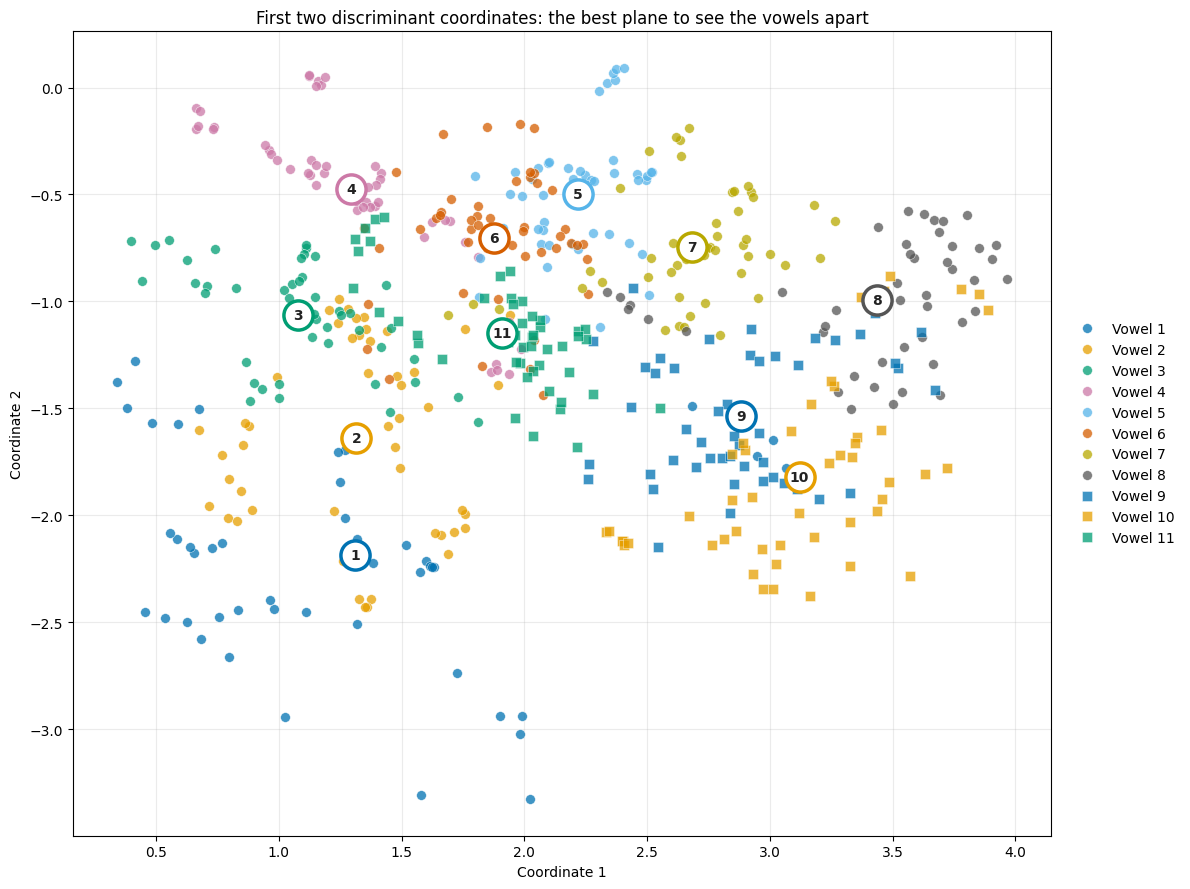

In [9]:
fig, ax = plt.subplots(figsize=(12, 9))
plot_coordinates(ax, 1, 2, legend=True, size=7)
ax.set_title('First two discriminant coordinates: the best plane to see the vowels apart')
plt.tight_layout()

The further we go in the coordinates, the less the centroids are separated: in the last ones they are all together.

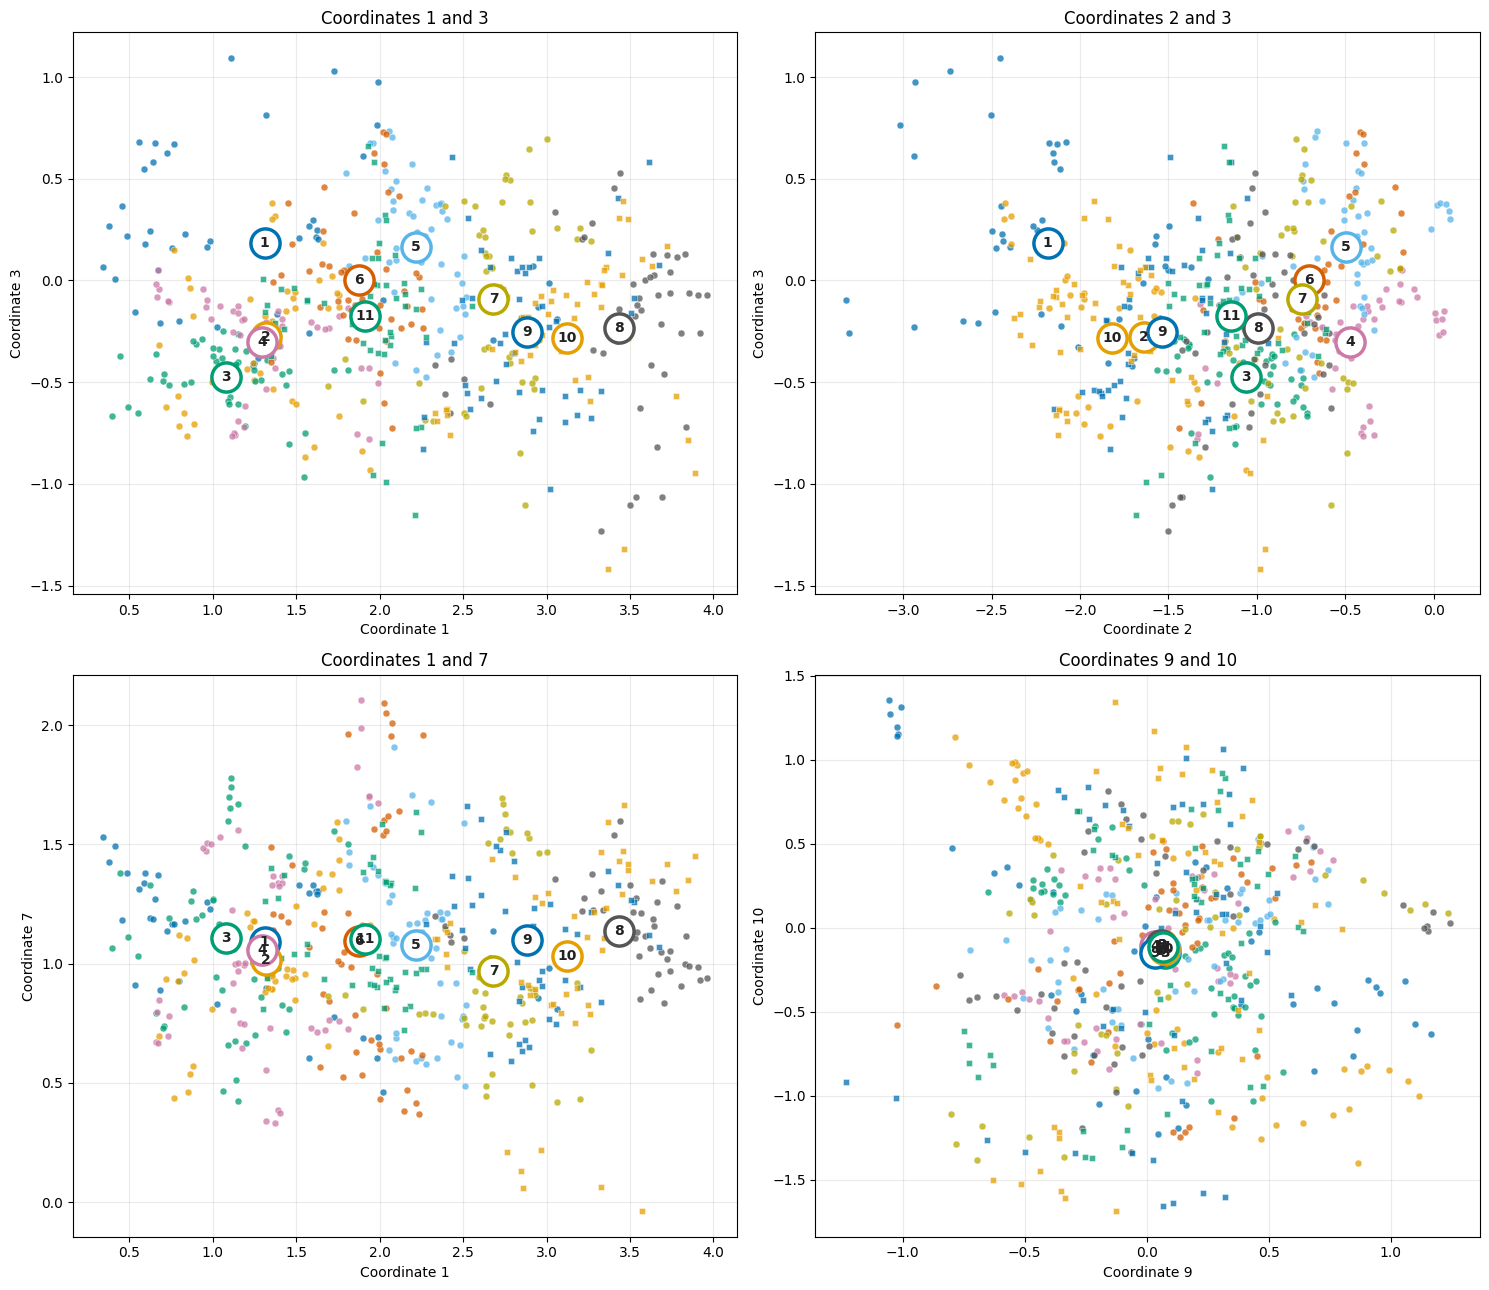

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 13))
for ax, (i, j) in zip(axes.ravel(), [(1, 3), (2, 3), (1, 7), (9, 10)]):
    plot_coordinates(ax, i, j)
    ax.set_title(f'Coordinates {i} and {j}')
plt.tight_layout()

## Classifying in the reduced space

Classifying with LDA in the plane of the first two coordinates is the same as assigning each point to the closest centroid (after sphering the data and taking into account the proportions of the classes). The decision regions are polygons.

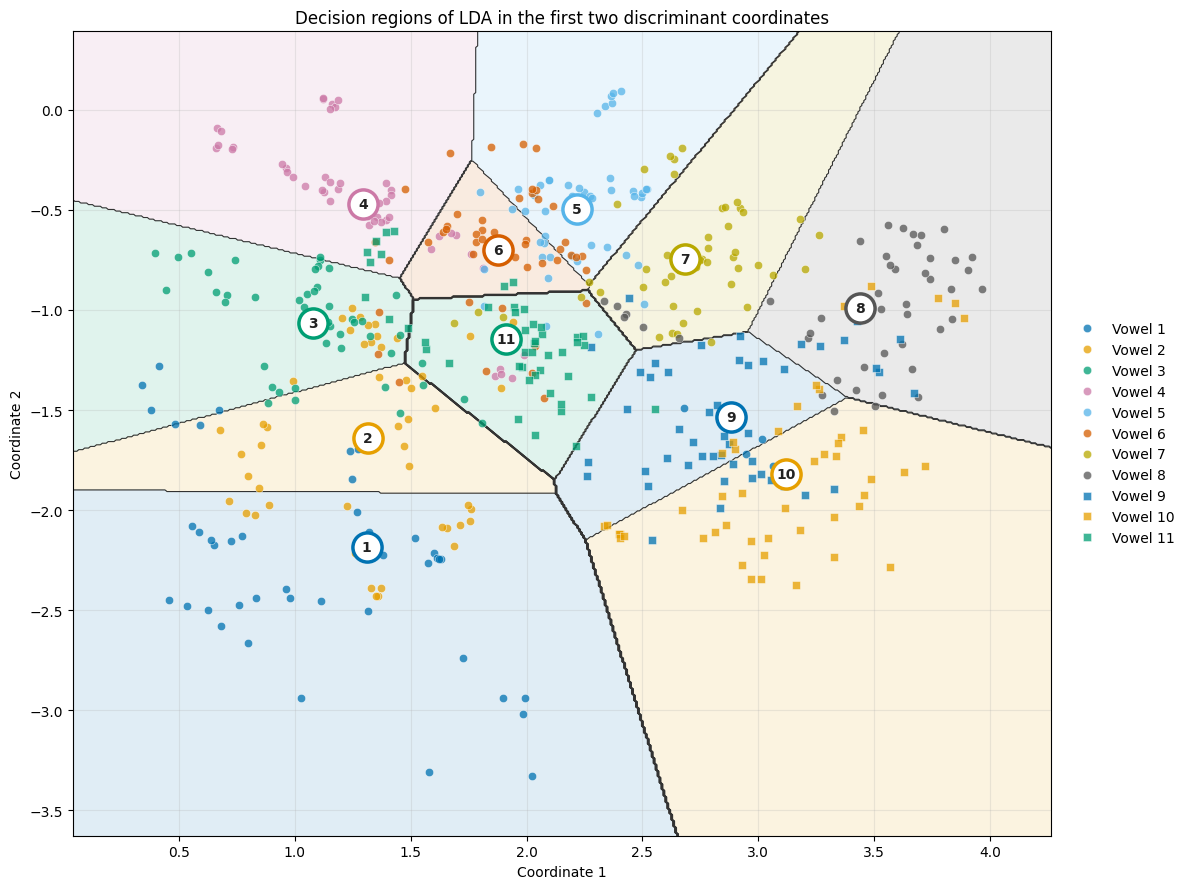

In [11]:
lda_2 = LinearDiscriminantAnalysis()
lda_2.fit(discriminant_coordinates[coordinate_names[:2]], dat_train['y'])

c1 = discriminant_coordinates['coordinate 1']
c2 = discriminant_coordinates['coordinate 2']
g1, g2 = np.meshgrid(np.linspace(c1.min()-0.3, c1.max()+0.3, 500), np.linspace(c2.min()-0.3, c2.max()+0.3, 500))
grid = pd.DataFrame(np.c_[g1.ravel(), g2.ravel()], columns=coordinate_names[:2])
Z = lda_2.predict(grid).reshape(g1.shape)

fig, ax = plt.subplots(figsize=(12, 9))
ax.contourf(g1, g2, Z, levels=np.arange(0.5, 12), colors=[class_colors[k] for k in classes], alpha=0.12)
ax.contour(g1, g2, Z, levels=np.arange(1.5, 11), colors='#333333', linewidths=0.8)
plot_coordinates(ax, 1, 2, legend=True, size=6)
ax.set_xlim(g1.min(), g1.max())
ax.set_ylim(g2.min(), g2.max())
ax.set_title('Decision regions of LDA in the first two discriminant coordinates')
plt.tight_layout()

## How many coordinates?

Reduced-rank LDA classifies using only the first $L$ discriminant coordinates. Using fewer coordinates can even reduce the testing error, because the last ones mostly add noise.

In [12]:
X_train_coord = dat_train[features].to_numpy() @ eigenvectors
X_test_coord = dat_test[features].to_numpy() @ eigenvectors

error_train = []
error_test = []
for L in range(1, 11):
    lda_L = LinearDiscriminantAnalysis().fit(X_train_coord[:, :L], dat_train['y'])
    error_train.append(100*np.mean(lda_L.predict(X_train_coord[:, :L]) != dat_train['y']))
    error_test.append(100*np.mean(lda_L.predict(X_test_coord[:, :L]) != dat_test['y']))

pd.DataFrame({'Training error (%)': error_train, 'Testing error (%)': error_test},
             index=pd.Index(range(1, 11), name='Coordinates')).round(1).T

Coordinates,1,2,3,4,5,6,7,8,9,10
Training error (%),61.2,35.0,33.0,33.0,31.6,30.1,31.2,31.8,31.4,31.6
Testing error (%),69.9,49.1,49.6,51.1,51.5,55.4,55.4,55.6,55.2,55.6


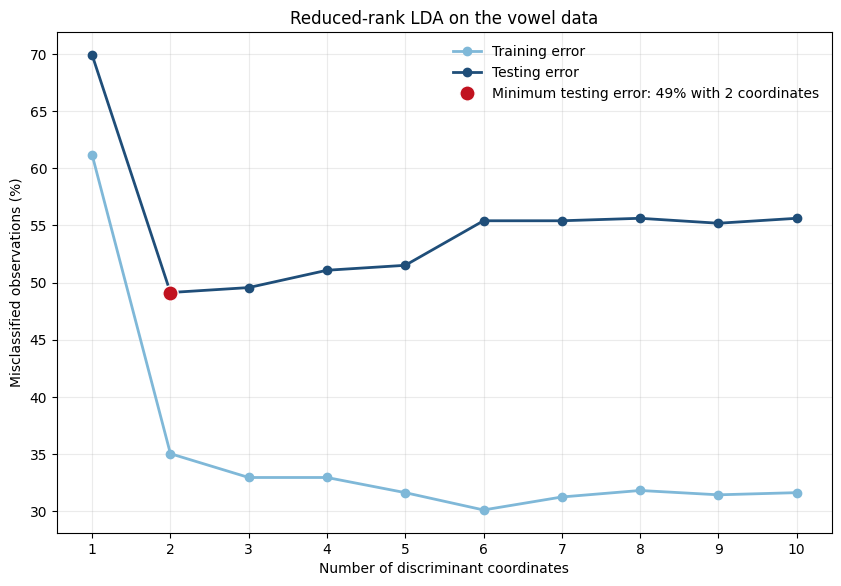

In [13]:
best = int(np.argmin(error_test))

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.plot(range(1, 11), error_train, 'o-', color='#7fb8d8', lw=2, label='Training error')
ax.plot(range(1, 11), error_test, 'o-', color='#1f4e79', lw=2, label='Testing error')
ax.plot(best+1, error_test[best], 'o', color='#c1121f', markersize=11, markeredgecolor='white', markeredgewidth=1,
        label=f'Minimum testing error: {error_test[best]:.0f}% with {best+1} coordinates')
ax.set_xticks(range(1, 11))
ax.set_xlabel('Number of discriminant coordinates')
ax.set_ylabel('Misclassified observations (%)')
ax.set_title('Reduced-rank LDA on the vowel data')
ax.legend(loc='upper right', frameon=False)
ax.grid(True, alpha=0.25)